<a href="https://colab.research.google.com/github/adarshpatel2366-wq/Adarsh-Patel/blob/main/case_study3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")

In [ ]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
462110,575961,23581,JUMBO BAG PAISLEY PARK,1,11/13/2011 12:29,2.08,16794.0,United Kingdom
462111,575961,23103,JINGLE BELL HEART DECORATION,1,11/13/2011 12:29,1.65,16794.0,United Kingdom
462112,575961,22993,SET OF 4 PANTRY JELLY MOULDS,2,11/13/2011 12:29,1.25,16794.0,United Kingdom
462113,575961,23198,PANTRY MAGNETIC SHOPPING LIST,6,11/13/2011 12:29,1.45,16794.0,United Kingdom


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
df.describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 462115 entries, 0 to 462114
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    462115 non-null  object 
 1   StockCode    462115 non-null  object 
 2   Description  460737 non-null  object 
 3   Quantity     462115 non-null  int64  
 4   InvoiceDate  462115 non-null  object 
 5   UnitPrice    462115 non-null  float64
 6   CustomerID   347829 non-null  float64
 7   Country      462115 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 28.2+ MB


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1378
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,114286
Country,0


In [ ]:
df_clean = df.copy()

df_clean.dropna(subset=['CustomerID'], inplace=True)

In [ ]:
df_clean.dropna(subset=['Description'], inplace=True)

In [ ]:
df_clean.drop_duplicates(inplace=True)

In [ ]:
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

In [ ]:
df_clean = df_clean[df_clean['Quantity'] > 0]

df_clean = df_clean[df_clean['UnitPrice'] > 0]

In [ ]:
print("Original Shape:", df.shape)

print("Cleaned Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicates:", df_clean.duplicated().sum())

Original Shape: (462115, 8)
Cleaned Shape: (335837, 8)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicates: 0


In [ ]:
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

print(df_clean['InvoiceDate'].dtype)
print(df_clean['InvoiceDate'].min())
print(df_clean['InvoiceDate'].max())

datetime64[ns]
2010-12-01 08:26:00
2011-11-13 12:29:00


In [ ]:
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

df_clean[['Quantity', 'UnitPrice', 'TotalPrice']].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [ ]:
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

print(snapshot_date)

2011-11-14 12:29:00


In [ ]:
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,300,1,77183.60
12347.0,14,6,4085.18
12348.0,49,4,1797.24
12350.0,284,1,334.40
12352.0,10,8,2506.04


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.150449,-0.424850,9.298317
12347.0,-0.821921,0.304508,0.273738
12348.0,-0.458169,0.012765,-0.008726
12350.0,1.984162,-0.424850,-0.189326
12352.0,-0.863492,0.596251,0.078781


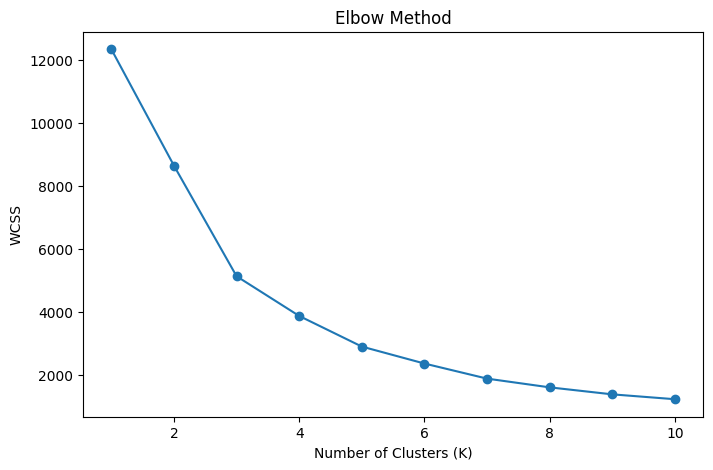

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,300,1,77183.60,3
12347.0,14,6,4085.18,0
12348.0,49,4,1797.24,0
12350.0,284,1,334.40,1
12352.0,10,8,2506.04,0


In [ ]:
print(rfm['Cluster'].value_counts().sort_index())

Cluster
0    2791
1    1131
2      11
3     181
Name: count, dtype: int64


In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster,DBSCAN_Cluster
CustomerID,,,,,
12346.0,300,1,77183.60,3,-1
12347.0,14,6,4085.18,0,0
12348.0,49,4,1797.24,0,0
12350.0,284,1,334.40,1,0
12352.0,10,8,2506.04,0,0


In [ ]:
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1      55
 0    4059
Name: count, dtype: int64


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=['PCA1', 'PCA2'],
    index=rfm.index
)

pca_df['Cluster'] = rfm['Cluster']

pca_df.head()

,PCA1,PCA2,Cluster
CustomerID,,,
12346.0,4.802468,5.594835,3
12347.0,0.687637,-0.597852,0
12348.0,0.174857,-0.417913,0
12350.0,-1.151201,1.671250,1
12352.0,0.776910,-0.675024,0


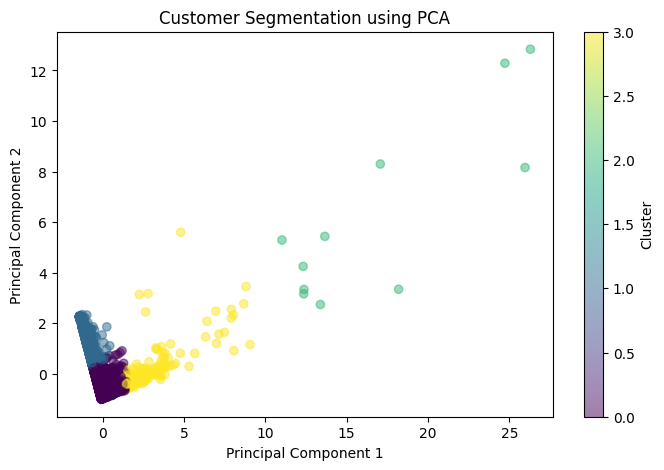

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PCA1'],
    pca_df['PCA2'],
    c=pca_df['Cluster'],
    cmap='viridis',
    alpha=0.5
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Segmentation using PCA')
plt.colorbar(label='Cluster')
plt.show()

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

rfm_tsne = tsne.fit_transform(rfm_scaled)

tsne_df = pd.DataFrame(
    rfm_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=rfm.index
)

tsne_df['Cluster'] = rfm['Cluster']

tsne_df.head()

,TSNE1,TSNE2,Cluster
CustomerID,,,
12346.0,23.010565,35.134319,3
12347.0,54.877636,7.141062,0
12348.0,30.245022,-13.722425,0
12350.0,2.002093,59.396755,1
12352.0,55.691734,20.437370,0


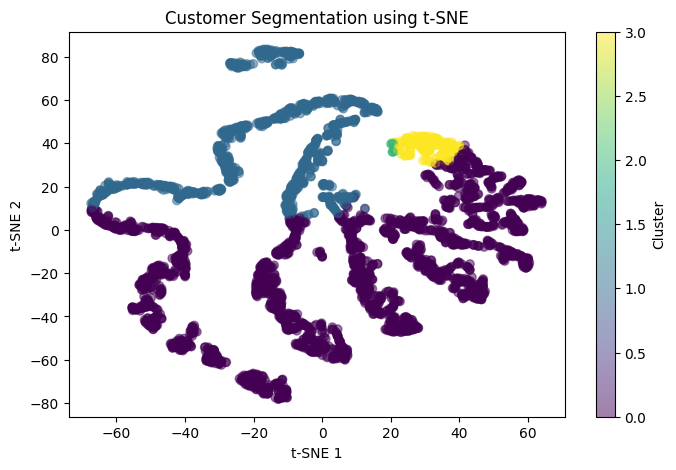

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_df['TSNE1'],
    tsne_df['TSNE2'],
    c=tsne_df['Cluster'],
    cmap='viridis',
    alpha=0.5
)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('Customer Segmentation using t-SNE')
plt.colorbar(label='Cluster')
plt.show()

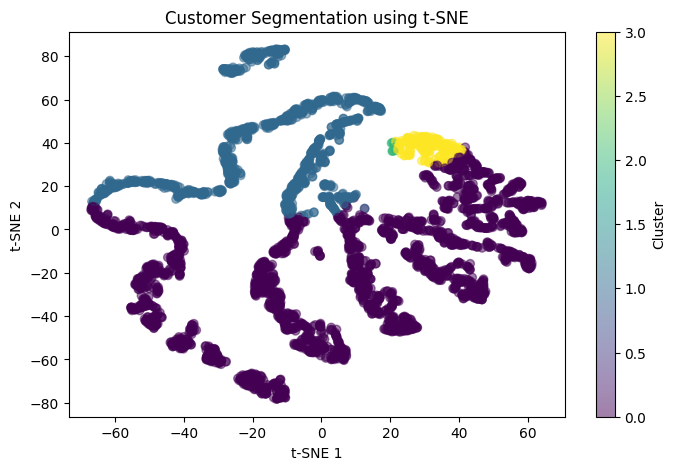

In [ ]:
from sklearn.manifold import TSNE

tsne_sample = rfm_scaled.sample(
    n=min(5000, len(rfm_scaled)),
    random_state=42
)

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

rfm_tsne = tsne.fit_transform(tsne_sample)

tsne_df = pd.DataFrame(
    rfm_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=tsne_sample.index
)

tsne_df['Cluster'] = rfm.loc[tsne_df.index, 'Cluster']

plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_df['TSNE1'],
    tsne_df['TSNE2'],
    c=tsne_df['Cluster'],
    cmap='viridis',
    alpha=0.5
)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('Customer Segmentation using t-SNE')
plt.colorbar(label='Cluster')
plt.show()


In [ ]:
# Group by Cluster and calculate the average for Recency, Frequency, and Monetary,
# as well as the total count of customers in each group.
cluster_analysis = rfm.groupby('Cluster').agg({
    'Recency': ['mean', 'count'],
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

# Flatten the column names to make them simple to read
cluster_analysis.columns = ['Recency_Mean', 'Total_Customers', 'Frequency_Mean', 'Monetary_Mean']

# Rearrange the columns for better presentation
cluster_analysis = cluster_analysis[['Total_Customers', 'Recency_Mean', 'Frequency_Mean', 'Monetary_Mean']]

print(cluster_analysis)

         Total_Customers  Recency_Mean  Frequency_Mean  Monetary_Mean
Cluster                                                              
0                   2791         42.26            3.47        1299.49
1                   1131        231.40            1.53         470.86
2                     11          5.82           82.36      116208.13
3                    181         17.79           20.86       12413.97


In [ ]:
# Group by DBSCAN Cluster and calculate averages,
# and use Recency count to find the customer distribution.
dbscan_analysis = rfm.groupby('DBSCAN_Cluster').agg({
    'Recency': ['mean', 'count'],
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

# Flatten column names simply
dbscan_analysis.columns = ['Recency_Mean', 'Total_Customers', 'Frequency_Mean', 'Monetary_Mean']

# Reorder the columns nicely
dbscan_analysis = dbscan_analysis[['Total_Customers', 'Recency_Mean', 'Frequency_Mean', 'Monetary_Mean']]

print(dbscan_analysis)

                Total_Customers  Recency_Mean  Frequency_Mean  Monetary_Mean
DBSCAN_Cluster                                                              
-1                           55         43.38           38.35       45011.45
 0                         4059         93.76            3.45        1283.32


In [ ]:
print("K-Means Results")
print("Number of Clusters:", rfm['Cluster'].nunique())
print("Customer Distribution:")
print(rfm['Cluster'].value_counts().sort_index())

print("\nDBSCAN Results")
print("Number of Clusters:",
      len(set(rfm['DBSCAN_Cluster']) - {-1}))

print("Noise Points:",
      (rfm['DBSCAN_Cluster'] == -1).sum())

print("Customer Distribution:")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

K-Means Results
Number of Clusters: 4
Customer Distribution:
Cluster
0    2791
1    1131
2      11
3     181
Name: count, dtype: int64

DBSCAN Results
Number of Clusters: 1
Noise Points: 55
Customer Distribution:
DBSCAN_Cluster
-1      55
 0    4059
Name: count, dtype: int64


In [ ]:
print(cluster_analysis)

         Total_Customers  Recency_Mean  Frequency_Mean  Monetary_Mean
Cluster                                                              
0                   2791         42.26            3.47        1299.49
1                   1131        231.40            1.53         470.86
2                     11          5.82           82.36      116208.13
3                    181         17.79           20.86       12413.97
